<div class='alert alert-block alert-info'>
<h1 align='center'>Mulitple Polynomial Regression</h1>
<h2 align='center'>Fuel Dataset (Multiple Features)</h2>
</div>

# Import Libraries

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Load Dataset

In [33]:
Train_df=pd.read_csv('data/auto-train-multi.csv')
Test_df=pd.read_csv('data/auto-test-multi.csv')
Train_df.head()

,cylinders,displacement,horsepower,weight,acceleration,year,mpg
0,0.2,0.059432,0.038043,0.051602,0.565476,0.416666,0.638298
1,1.0,0.728682,0.646739,0.754466,0.238095,0.166667,0.106383
2,0.2,0.124031,0.157609,0.154522,0.446429,0.250000,0.398936
3,0.0,0.005168,0.239130,0.144882,0.327381,0.250000,0.239362
4,1.0,0.857881,0.728261,0.739155,0.184524,0.583333,0.186170


# Split Feature, Target

In [34]:
x_train=Train_df.iloc[:,:-1]
y_train=Train_df.iloc[:,-1]

x_test=Test_df.iloc[:,:-1]
y_test=Test_df.iloc[:,-1]

# EDA

In [35]:
print(Train_df.info(),'\n')
Train_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 352 entries, 0 to 351
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cylinders     352 non-null    float64
 1   displacement  352 non-null    float64
 2   horsepower    352 non-null    float64
 3   weight        352 non-null    float64
 4   acceleration  352 non-null    float64
 5   year          352 non-null    float64
 6   mpg           352 non-null    float64
dtypes: float64(7)
memory usage: 19.4 KB
None 



,cylinders,displacement,horsepower,weight,acceleration,year,mpg
count,352.000000,352.000000,352.000000,352.000000,352.000000,352.000000,352.000000
mean,0.488068,0.320410,0.311512,0.384101,0.452330,0.501420,0.385434
std,0.339725,0.264888,0.200227,0.241025,0.159629,0.303766,0.204968
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.200000,0.077519,0.161685,0.172030,0.349702,0.250000,0.226064
50%,0.200000,0.208010,0.250000,0.335838,0.446429,0.500000,0.372340
75%,1.000000,0.501292,0.429348,0.558194,0.537202,0.750000,0.531915
max,1.000000,1.000000,0.972826,1.000000,1.000000,1.000000,1.000000


In [36]:
def ax_plot(rows, cols, feature, target):
    fig, ax=plt.subplots(rows, cols, figsize=(15,10))
    ax=ax.flatten()
    feature_num=feature.shape[1]
    for ind in range(feature_num):
        ax[ind].set_title(f'Fuel consumtion vs. {feature.columns[ind]}')
        ax[ind].set_xlabel(f'{feature.columns[ind]}')
        ax[ind].set_ylabel('Fuel consumtion')
        ax[ind].scatter(feature.iloc[:,ind], target)

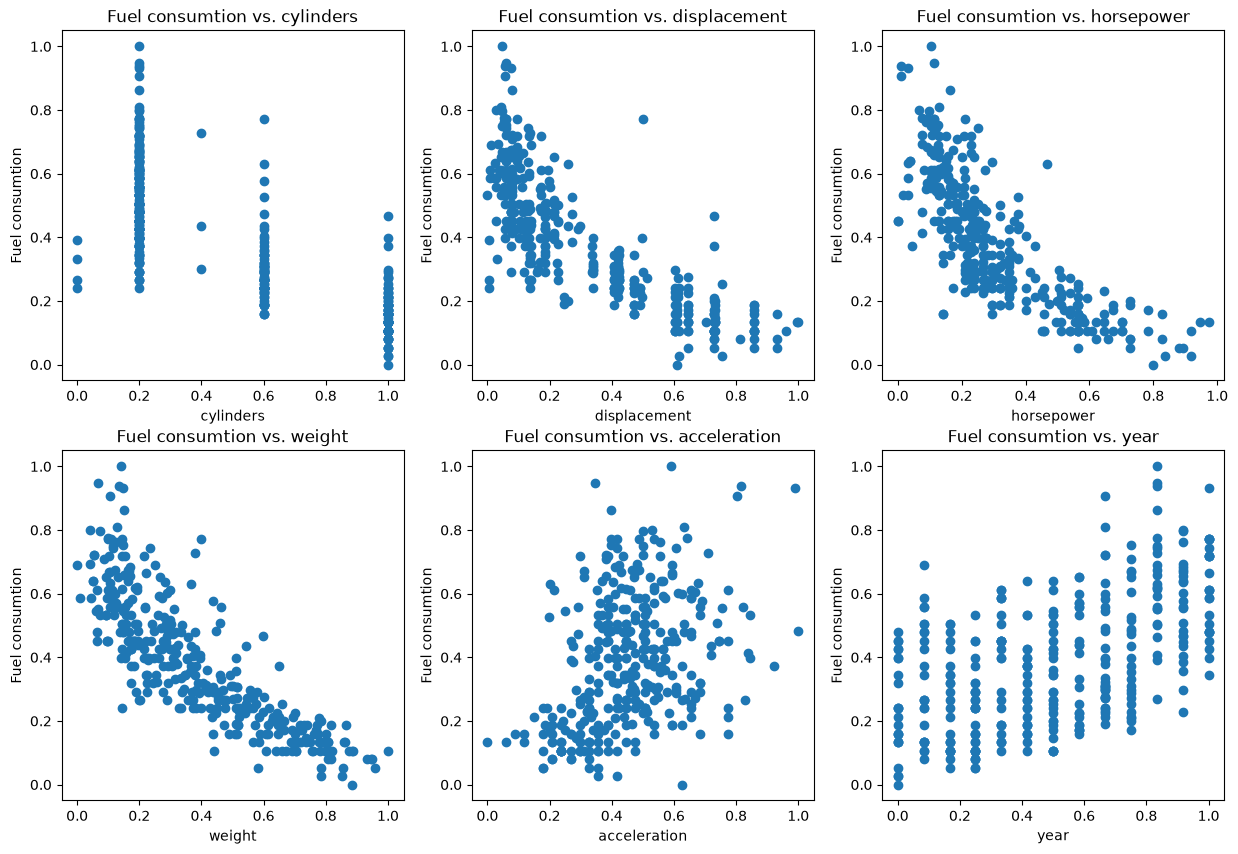

In [37]:
ax_plot(2,3, x_train, y_train)

# Required Functions

In [38]:
class Closed_Form_Linear_Regression(BaseEstimator, RegressorMixin):
    '''Linear Regression with Normal Equation (closed-form solution)
    weight=(transpose(x)*x)^-1 *transpose(x)* y '''
    def __init__(self):
        self.weight_=None

    def fit(self,x,y):
        square_matrix=x.T @ x
        self.weight_= np.linalg.inv(square_matrix) @ (x.T @ y)
        return self

    def predict(self, x):
        return x @ self.weight_

# Training

In [39]:
model_piped=make_pipeline(PolynomialFeatures(degree=3),
                        Closed_Form_Linear_Regression())
model_piped.steps

[('polynomialfeatures', PolynomialFeatures(degree=3)),
 ('closed_form_linear_regression', Closed_Form_Linear_Regression())]

In [40]:
model_piped.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('closed_form_linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['cylinders','displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",3
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


# Evaluation Metrics

In [41]:
y_pred=model_piped.predict(x_test)
score_for_train_dataset=model_piped.score(x_train, y_train)
score_for_test_dataset=model_piped.score(x_test, y_test)

score_df=pd.DataFrame({'Train dataset':round(score_for_train_dataset, 3),
                       'Test dataset':round(score_for_test_dataset, 3)}, 
                       index=['Score'])
score_df

,Train dataset,Test dataset
Score,0.924,0.841
